In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from collections import Counter
import os
import time
import ast
from scipy.stats import randint

In [2]:
from network_tools import read_dag_file, add_risk_parameters, compute_topological_indicators, visualize_dag
from simulation_tools import simulation, compute_times, evaluate_model

In [3]:
sns.set_theme(palette='tab10')

## MT Dataset (Vanhoucke 2009)
4,100 generated project networks proposed in the book Vanhoucke, M. (2009). Measuring time: Improving project performance using earned value management (Vol. 136). Springer Science & Business Media. [link](https://link-springer-com.ubu-es.idm.oclc.org/book/10.1007/978-1-4419-1014-1)

[Dataset source](https://www.projectmanagement.ugent.be/research/data)

[Information of the dataset](./dataset/MT_Vanhoucke/MT30/Info%20Datasets%20Measuring%20Time.pdf)



In [4]:
# Sample of netorks with topological indicators calculated
parameters=pd.read_csv('dataset\RCPLIB (Parameters and BKS) V6.csv', sep=';',low_memory=False)
parameters['Set']=parameters['FileName'].apply(lambda x: x.split('\\')[0])
parameters=parameters[parameters['Set']=="Set 1 SP"].copy()
parameters['Net']=parameters['FileName'].apply(lambda x: x.split(' | ')[0].split('\\')[1])
parameters=parameters.loc[(parameters['SetName']=='NetRes1k') & (parameters['Set']=="Set 1 SP"),
               ['#Act', 'CNC', 'OS','SP', 'AD', 'LA', 'I5', 'TF','Set','Net']].drop_duplicates().sort_values(by='Net').copy()
parameters.reset_index(drop=True, inplace=True)
parameters


,#Act,CNC,OS,SP,AD,LA,I5,TF,Set,Net
0,30,"0,67","0,05","0,07","0,44","0,03","0,75","0,56",Set 1 SP,EV1.rcp
1,30,"2,13","0,33","0,17","0,45","0,10","0,69","0,42",Set 1 SP,EV101.rcp
2,30,"1,23","0,20","0,28","0,54","0,07","0,67","0,75",Set 1 SP,EV201.rcp
3,30,"2,17","0,68","0,38","0,33","0,13","0,78","0,25",Set 1 SP,EV301.rcp
4,30,"1,63","0,88","0,48","0,36","0,28","0,95","0,05",Set 1 SP,EV401.rcp
5,30,"1,13","0,65","0,59","0,53","0,00","0,66","0,43",Set 1 SP,EV501.rcp
6,30,"1,17","0,75","0,69","0,70","0,00","0,49","0,38",Set 1 SP,EV601.rcp
7,30,"1,20","0,94","0,79","0,78","0,29","0,83","0,13",Set 1 SP,EV701.rcp
8,30,"1,07","0,95","0,90","0,96","0,00","0,77","0,22",Set 1 SP,EV801.rcp


### Topolgy complexity indicators by Vanhoucke
Vanhoucke, M., Coelho, J., Debels, D., Maenhout, B., & Tavares, L. V. (2008). An evaluation of the adequacy of project network generators with systematically sampled networks. _European Journal of Operational Research_, _187_(2), 511-524 [link](https://www.sciencedirect.com/science/article/pii/S037722170700375X?casa_token=go72ZhougbEAAAAA:TQysSbHF62mcFwBkTsXllickiVKCLumUkRtoCppi1Q3ytHYW5AY9je3IvUpz1_ORngV3CeBwAg)

The topology complexity of a project is described by the next indcators:
- Serial or parallel network (SP): it measures how close the network is a completely serial or completely parallel structure. 
- Activity distribution (AD): it is the standard deviation (normalized) of the width of each level of the topological order.
- Length of arcs (LA): it measures the proportion of long arcs in the DAG (those dependencies between nodes that are not between consecutive levels of the topological order)
- Topological float (TF): it measures the average flexibility of the activities, how much they can be delayed without affecting the total duration of the project.


SP= 0.33, AD= 0.67, LA= 0.07, TF= 0.44


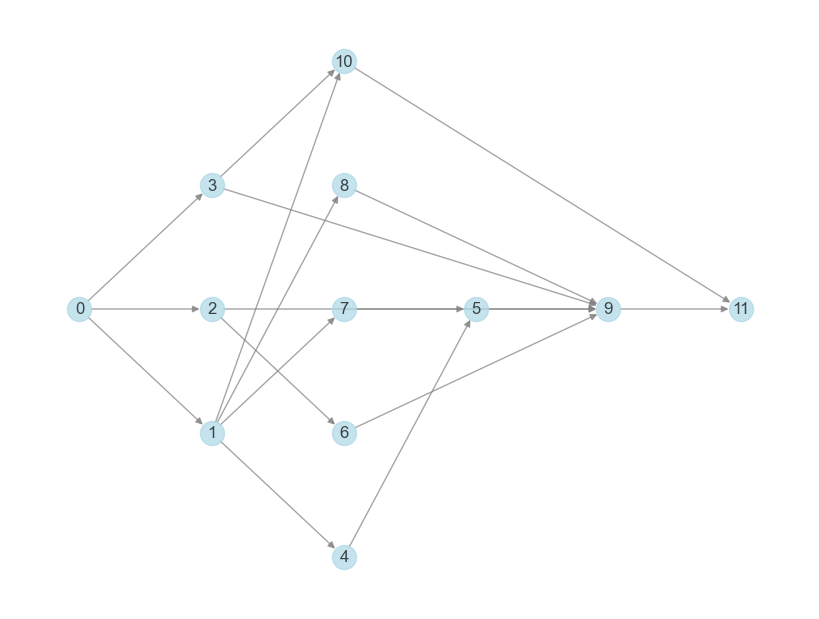

In [5]:
# Example
# Vanhoucke, M., Coelho, J., Debels, D., & Tavares, L. (2004). On the morphological structure of a network.
# https://repository.vlerick.com/entities/publication/1e581d60-93f6-492f-b7f4-5ff029c20455
g=nx.DiGraph()
g.add_edges_from([(0,1),(0,2),(0,3),(1,4),(1,7),(1,8),(1,10),(2,5),(2,6),(3,9),(3,10),(4,5),(5,9),(6,9),(7,9),(8,9),(9,11),(10,11)])
sp, ad, la, tf = compute_topological_indicators(g)
print("SP= %0.2f, AD= %0.2f, LA= %0.2f, TF= %0.2f" % (sp, ad, la, tf))
visualize_dag(g)

AON of the file EV401.rcp
SP = 0,48,AD = 0,36,LA = 0,28,TF = 0,05


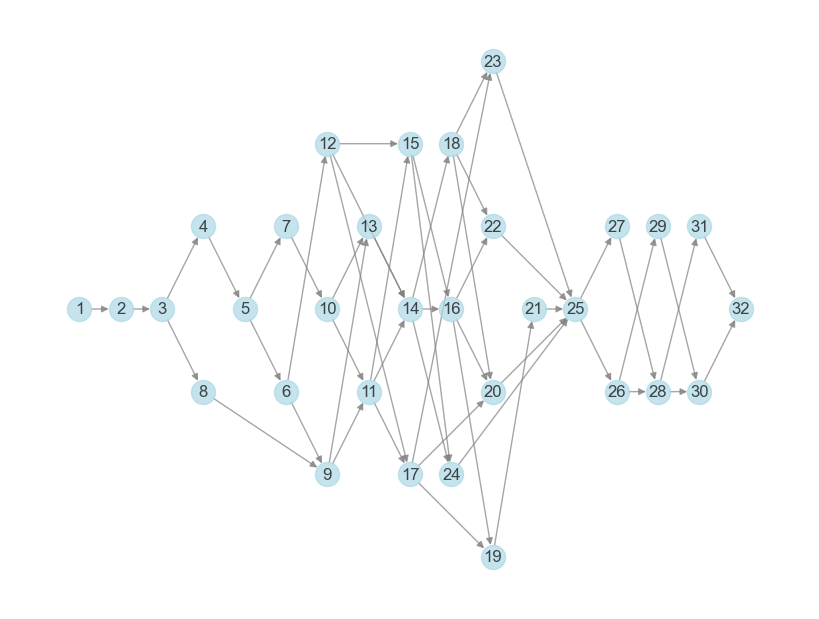

In [6]:
# Example
i=4 # netowrk index
G = read_dag_file('dataset\\Set 1 SP\\'+parameters.loc[i,'Net'])
print("AON of the file " + parameters.loc[i,'Net'])
print(f"SP = {parameters.loc[i,'SP']},AD = {parameters.loc[i,'AD']},LA = {parameters.loc[i,'LA']},TF = {parameters.loc[i,'TF']}")
visualize_dag(G)

## Monte Carlo Simulation

### Simulations

In [10]:
# Example
i=4 # netowrk index

project_name=parameters.loc[i,'Net'].split('.')[0]

G = read_dag_file('dataset\\Set 1 SP\\'+parameters.loc[i,'Net'])
add_risk_parameters(G,optim=0.8, mostprob=1.1, pessim=1.2)
print('Simulation for ' + project_name +' ...')

# Simulation
Ns=1000 # Number of simulation runs
start_time = time.time()
simulation(G.copy(),project_name=project_name, experiment="",Nruns=Ns)
print(f"Monte Carlo Simulation took {time.time() - start_time} seconds to run {Ns} samples")

Simulation for EV401 ...
Monte Carlo Simulation took 4.368924379348755 seconds to run 1000 samples


### Critical index

In [11]:
# Read simulation results
G = read_dag_file('dataset/Set 1 SP/EV401.rcp')
add_risk_parameters(G,optim=0.8, mostprob=1.1, pessim=1.2)
df_sim=pd.read_csv('./data/EV401/EV401_simulation_exploratory.csv',index_col=0)
N=df_sim.shape[0] # Number of samples

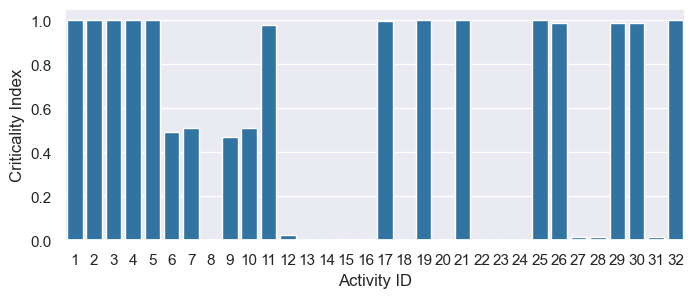

In [12]:
# Criticality index of activities
criticality_index={n:0 for n in G.nodes()}
for i,v in Counter(df_sim['critical_path'].apply(lambda x: ast.literal_eval(x)).sum()).items():
    criticality_index[i]=v/N
g=sns.barplot(x=list(criticality_index.keys()), y=list(criticality_index.values()))
g.set_xlabel('Activity ID')
g.set_ylabel('Criticality Index')
g.figure.set_size_inches(8,3)

### Histogram of project duration

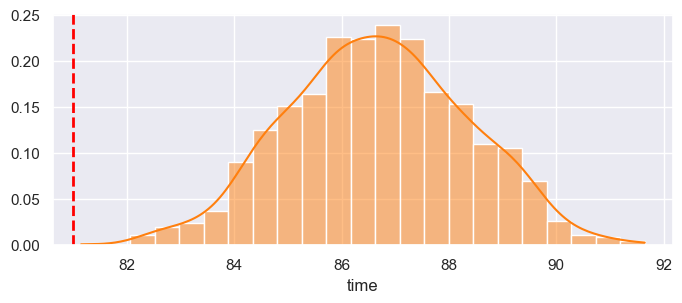

In [13]:
# Histogram of project duration
g=sns.histplot(df_sim['actual_duration'],stat='density',kde=True,color=sns.color_palette("tab10")[1],)
plt.axvline(x=df_sim.loc[0,'baseline_duration'], color='red', linestyle='--', linewidth=2,label='Baseline duration')
g.set_xlabel('time')
g.set_ylabel('')
#g.set_title("Histogram of project duration")
g.figure.set_size_inches(8,3)

In [14]:
s,f=compute_times(G,time='duration0')
print(f"Baseline duration: {np.max([t for t in f.values()])}")

Baseline duration: 81


In [15]:
s,f=compute_times(G,time='Optimistic')
print(f"Duration (optimistic): {np.max([t for t in f.values()])}")
s,f=compute_times(G,time='MostLikely')
print(f"Duration (most likely): {np.max([t for t in f.values()])}")
s,f=compute_times(G,time='Pessimistic')
print(f"Duration (pessimistic): {np.max([t for t in f.values()])}")

Duration (optimistic): 64.8
Duration (most likely): 89.1
Duration (pessimistic): 97.19999999999999


## Model selection

In [6]:
# Reegression models
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost.sklearn import XGBRegressor
from interpret.glassbox import ExplainableBoostingRegressor

In [7]:
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.metrics import mean_squared_error

In [8]:
# random seed
seed=1123

In [47]:
# Regression problem
project_name='EV401'
if os.path.exists('./data/'+project_name+'/'+project_name+'_simulation_exploratory.csv'):
    df_sim=pd.read_csv('./data/'+project_name+'/'+project_name+'_simulation_exploratory.csv',index_col=0)
    y=df_sim.loc[:,'actual_duration']
    X=df_sim.loc[:,[ c for c in df_sim.columns if c[:8]=='duration']]
else:
    print(f"Simulation file for the project {project_name} does not exist")


In [43]:
# outer kfolds
Nf=5 # number of outer folds
kfold = KFold(n_splits=Nf, random_state=seed,shuffle=True)
# save outer kfolds
kfs=pd.DataFrame([],columns=['kn','type','i'])
k=0
for train_index, test_index in kfold.split(X):
  p1=pd.DataFrame(train_index,columns=['i'])
  p1['kn']=k
  p1['type']='train'
  p2=pd.DataFrame(test_index,columns=['i'])
  p2['kn']=k
  p2['type']='test'
  p1=pd.concat([p1,p2],ignore_index=True)
  kfs=pd.concat([kfs,p1],ignore_index=True)
  k+=1
kfs.reset_index(inplace=True,drop=True)
kfs.to_csv('./data/'+project_name+'/'+project_name+'_regression_model_selection_kf_index.csv')

In [ ]:
# load outer kfolds
#kfs=pd.read_csv('./data/'+project_name+'/'+project_name+'_regression_model_selection_kf_index.csv',index_col=0)

### Test error estimation for a model

In [ ]:
import time
import os
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.metrics import mean_squared_error

In [48]:
def evaluate_model(X, y, model, param_dist, project_name, model_name=None, 
                   n_splits=5, n_iter=10, random_seed=42, n_jobs=6, echo=True, save=True):
    """
    Evaluate a machine learning model using KFold cross-validation and RandomizedSearchCV for hyperparameter tuning.

    Parameters:
        X (pd.DataFrame): Feature data.
        y (pd.Series or array-like): Target variable.
        model: An instance of a machine learning model (e.g., RandomForestRegressor()).
        param_dist (dict): Dictionary of parameter distributions for tuning.
        project_name (str): Project name for building the output file path.
        model_name (str): Name for the model. Defaults to model.__class__.__name__ if None.
        n_splits (int): Number of folds for cross-validation.
        n_iter (int): Number of iterations for RandomizedSearchCV.
        random_seed (int): Seed for reproducibility.
        n_jobs (int): Number of jobs to run in parallel.

    Returns:
        list: List of mean squared errors for each fold.
    """
    if model_name is None:
        model_name = model.__class__.__name__
    
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=random_seed)
    mse_folds = []
    start_time = time.time()
    
    for fold, (train_index, test_index) in enumerate(kfold.split(X)):
        if echo:
            print(f'Running fold {fold}...')
        search = RandomizedSearchCV(
            model,
            param_distributions=param_dist,
            n_iter=n_iter,
            n_jobs=n_jobs,
            random_state=random_seed
        )
        search.fit(X.iloc[train_index, :], y.iloc[train_index])
        y_pred = search.best_estimator_.predict(X.iloc[test_index, :])
        mse = mean_squared_error(y.iloc[test_index], y_pred)
        mse_folds.append(mse)
    
    total_time = time.time() - start_time
    if echo:
        print(f"{model_name} took {total_time:.2f} seconds to run {n_splits} folds")
    
    if save:
        results_df = pd.DataFrame(
            [mse_folds],
            columns=[f'mse{i+1}' for i in range(len(mse_folds))]
        )
        output_path = os.path.join('.', 'data', project_name, 
                               f"{project_name}_regression_model_selection_{model_name}.csv")
        results_df.to_csv(output_path, index=False)
    return mse_folds



### Random Forest model

In [49]:
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import randint

In [52]:
mse_results = evaluate_model(X, y, RandomForestRegressor(random_state=seed), 
                             param_dist={
                                "n_estimators": randint(100, 1000),
                                "max_depth": randint(1, 10)},
                              project_name='EV401',echo=True,save=True)

Running fold 0...
Running fold 1...
Running fold 2...
Running fold 3...
Running fold 4...
RandomForestRegressor took 353.96 seconds to run 5 folds


In [53]:
mse_results

[0.8416489500975143,
 0.7398988109637478,
 0.9340648228384478,
 0.7750871317421955,
 0.987964066675626]

In [11]:
from scipy.stats import randint

In [44]:
# RandomForestRegressor
# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

model='RFR'
mse_kf=[]
k=0
start_time = time.time()
for train_index, test_index in kfold.split(X):
  print('running %i...'%k)
  # parameter optimization in the inner folds
    # n_estimators: number of trees
    # max_depth of the trees
  mdr = RandomizedSearchCV(RandomForestRegressor(),
                    param_distributions={"n_estimators": randint(100,1000), 
                            "max_depth": randint(1,10)},
                    n_jobs=6,n_iter=10)
  mdr.fit(X.iloc[train_index,:], y.iloc[train_index])
  
  # score of the best model in the outer fold
  mse_kf.append(mean_squared_error(y.iloc[test_index],mdr.best_estimator_.predict(X.iloc[test_index,:])))
  k+=1
print(f"RandomForestRegressor took {time.time() - start_time} seconds to run {Nf} folds")
pd.DataFrame([mse_kf],columns=['mse'+str(i+1) for i in range(len(mse_kf))]).to_csv('./data/'+project_name+'/'+project_name+'_regression_model_selection_'+model+'.csv',index=False) 

running 0...
running 1...
running 2...
running 3...
running 4...
RandomForestRegressor took 355.93452525138855 seconds to run 5 folds


### EBM model

In [ ]:
# ExplainableBoostingRegressor
# https://interpret.ml/docs/python/api/ExplainableBoostingRegressor.html
model='ExplainableBoostingR'
k=0
for train_index, test_index in kfold.split(X):
  print('running %i...'%k)
  # parameter optimization in the inner folds
    # inner_bags: number of inner bags.
    # max_leaves: maximum leaf nodes used in boosting.
    # outer_bags: number of outer bags.
  mdr = GridSearchCV(ExplainableBoostingRegressor(),param_grid={"inner_bags": np.linspace(0,6,3).astype('int'),
                                                                 "max_leaves": np.linspace(1,3,3).astype('int')},n_jobs=6)    

  mdr.fit(X.iloc[train_index,:], y.iloc[train_index])
  
  # score of the best model in the outer fold
  results = pd.concat([results,pd.DataFrame([[model,k, mean_squared_error(y.iloc[test_index],mdr.best_estimator_.predict(X.iloc[test_index,:]))]],columns=['model','kf','MSE'])],ignore_index=True)
  
  k+=1

In [ ]:
results.to_csv('./data/EV401_regression_ebm_results.csv',index=False)

### Gradient Boosting model

In [ ]:
# GradientBoostingRegressor
# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html
model='GradientBoostingR'
k=0
for train_index, test_index in kfold.split(X):
  print('running %i...'%k)
  # parameter optimization in the inner folds
    # n_estimators: number of  boosting stages
    # max_depth of the regression estimators
  mdr = GridSearchCV(GradientBoostingRegressor(),
                    param_grid={"n_estimators": np.linspace(100,1000,5).astype('int'),  
                                "max_depth": np.linspace(1,10,5).astype('int')},
                    n_jobs=6)  
  mdr.fit(X.iloc[train_index,:], y.iloc[train_index])
  
  # score of the best model in the outer fold
  results = pd.concat([results, pd.DataFrame([[model,k, mean_squared_error(y.iloc[test_index],mdr.best_estimator_.predict(X.iloc[test_index,:]))]],columns=['model','kf','MSE'])],ignore_index=True)
  k+=1

In [ ]:
results.to_csv('./data/EV401_regression_gb_results.csv',index=False)

### XGB model

In [ ]:
# XGBRegressor
# https://xgboost.readthedocs.io/en/stable/python/python_api.html#module-xgboost.sklearn
model='XGBoostR'
k=0
for train_index, test_index in kfold.split(X):
  print('running %i...'%k)
  # parameter optimization in the inner folds
    # n_estimators: number of gradient boosted trees
    # max_depth: maximum tree depth for base learners
  mdr = GridSearchCV(XGBRegressor(verbosity = 0),
                    param_grid={"n_estimators": np.linspace(100,1000,5).astype('int'),  
                                "max_depth": np.linspace(1,10,5).astype('int')},
                    n_jobs=6)    
  mdr.fit(X.iloc[train_index,:], y.iloc[train_index])
  
  # score of the best model in the outer fold
  results = pd.concat([results, pd.DataFrame([[model,k, mean_squared_error(y.iloc[test_index],mdr.best_estimator_.predict(X.iloc[test_index,:]))]],columns=['model','kf','MSE'])],ignore_index=True)
  k+=1

In [ ]:
results.to_csv('./data/EV401_regression_xgb_results.csv',index=False)

### Benchmarking

In [ ]:
# Save results
results.drop(results[results.model=='none'].index,inplace=True)
results.reset_index(inplace=True,drop=True)
results.to_csv('./data/EV401_regression_model_selection_results.csv')

In [ ]:
# Load results
results=pd.read_csv('./data/regression_model_selection_results.csv',index_col=0)

In [ ]:
# Average MSE over 5-fold cross-validation
results.groupby('model').agg({'MSE':['mean','std']}).sort_values(by=('MSE', 'mean'))